In [1]:
# Відтворюваність лабораторної роботи
RANDOM_SEED = 2026005

import random
import numpy as np

random.seed(RANDOM_SEED)
np.random.seed(RANDOM_SEED)
print(f"random_seed = {RANDOM_SEED}")

random_seed = 2026005


# Лабораторна робота №1 — очищення даних
## Варіант 005: Фінанси — карткові транзакції, комісії та FX

**Мета:** згенерувати синтетичну історію карткових транзакцій з контрольованими проблемами якості, провести діагностику, реалізувати очищення, валідацію, порівняння «до/після» та розрахувати 10 KPI.

У роботі використано Python: `pandas`, `numpy`, `matplotlib`. Дані генеруються відтворювано завдяки фіксованому `RANDOM_SEED`.


In [2]:
from pathlib import Path
import re
import unicodedata
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

pd.set_option('display.max_columns', 50)
pd.set_option('display.width', 160)
pd.set_option('display.float_format', lambda x: f'{x:,.4f}')

ROOT = Path.cwd()
if ROOT.name == 'notebooks':
    ROOT = ROOT.parent

RAW_DIR = ROOT / 'data' / 'raw'
CLEAN_DIR = ROOT / 'data' / 'clean'
OUT_DIR = ROOT / 'outputs'
FIG_DIR = OUT_DIR / 'figures'
for p in [RAW_DIR, CLEAN_DIR, OUT_DIR, FIG_DIR]:
    p.mkdir(parents=True, exist_ok=True)

RAW_PATH = RAW_DIR / 'generated_dirty.csv'
CLEAN_PATH = CLEAN_DIR / 'dataset_clean.csv'
CHANGE_LOG_PATH = ROOT / 'change_log.csv'

print('Project root:', ROOT.resolve())

Project root: C:\Users\Andriy\Desktop\lab01_finance_cleaning


# Блок 1. Генерація синтетичних даних

Генеруємо базові транзакції за квартал, а потім навмисно додаємо контрольований «бруд»: пропуски, повні та майже дублікати, змішані формати дат і сум, нестабільні категорії, помилки FX, часові нелогічності та проблемні чарджбеки.


In [3]:
# --- Допоміжні довідники для генерації ---
rng = np.random.default_rng(RANDOM_SEED)

N_BASE = 8600
N_CLIENTS = 2400
N_FULL_DUP = 180
N_NEAR_DUP = 180

clients = [f'CL{i:05d}' for i in range(1, N_CLIENTS + 1)]
client_cards = {}
for client in clients:
    n_cards = int(rng.integers(1, 4))
    client_cards[client] = [f'{client}-C{j}' for j in range(1, n_cards + 1)]

currencies = np.array(['UAH', 'USD', 'EUR', 'PLN'])
currency_probs = np.array([0.72, 0.12, 0.10, 0.06])
base_fx = {'UAH': 1.0, 'USD': 41.2, 'EUR': 45.0, 'PLN': 10.55}

mcc_values = ['5411', '5812', '5814', '5541', '5912', '5732', '5651', '4111', '6011', '7399', '7995', '4814']
merchants_by_mcc = {
    '5411': ['Silpo', 'ATB Market', 'Novus'],
    '5812': ['Puzata Hata', 'Urban Space Cafe', 'Local Bistro'],
    '5814': ['McDonalds', 'KFC', 'Burger Point'],
    '5541': ['WOG', 'OKKO', 'UPG'],
    '5912': ['Apteka 911', 'ANC Pharmacy', 'Podorozhnyk'],
    '5732': ['Comfy', 'Foxtrot', 'Tech Store'],
    '5651': ['Reserved', 'House', 'Fashion Point'],
    '4111': ['Ukrzaliznytsia', 'City Transport', 'Rail Service'],
    '6011': ['ATM Cash', 'Bank ATM', 'Cash Point'],
    '7399': ['Freelance Service', 'Digital Service', 'Business Hub'],
    '7995': ['Game Service', 'Entertainment Hub', 'Play Center'],
    '4814': ['Kyivstar', 'Vodafone UA', 'Lifecell']
}

countries = np.array(['UA', 'PL', 'DE', 'CZ', 'US', 'FR', 'IT', 'ES', 'GB'])
country_probs = np.array([0.74, 0.07, 0.04, 0.03, 0.03, 0.025, 0.025, 0.02, 0.02])
cities = {
    'UA': ['Kyiv', 'Lviv', 'Rivne', 'Odesa', 'Dnipro', 'Kharkiv'],
    'PL': ['Warsaw', 'Krakow', 'Wroclaw'],
    'DE': ['Berlin', 'Munich', 'Hamburg'],
    'CZ': ['Prague', 'Brno'],
    'US': ['New York', 'Chicago', 'Boston'],
    'FR': ['Paris', 'Lyon'],
    'IT': ['Rome', 'Milan'],
    'ES': ['Madrid', 'Barcelona'],
    'GB': ['London', 'Manchester']
}

notes = [None, None, None, 'subscription', 'travel', 'family purchase', 'cash withdrawal', 'online order']

start = pd.Timestamp('2026-04-01 00:00:00')
end = pd.Timestamp('2026-06-30 23:59:59')
span_seconds = int((end - start).total_seconds())

# Основні ідентифікатори
client_id = rng.choice(clients, size=N_BASE, replace=True)
card_id = np.array([rng.choice(client_cards[c]) for c in client_id])
txn_id = np.array([f'TXN{i:07d}' for i in range(1, N_BASE + 1)])

# Час авторизації та постингу
operation_at_dt = start + pd.to_timedelta(rng.integers(0, span_seconds + 1, size=N_BASE), unit='s')
posting_delay_hours = rng.uniform(0, 72, size=N_BASE)
posted_at_dt = operation_at_dt + pd.to_timedelta(posting_delay_hours, unit='h')

# Канал, валюта, країна
channel_clean = rng.choice(['POS', 'ECOM', 'ATM'], size=N_BASE, p=[0.66, 0.25, 0.09])
currency_clean = rng.choice(currencies, size=N_BASE, p=currency_probs)
country_clean = rng.choice(countries, size=N_BASE, p=country_probs)
city_clean = np.array([rng.choice(cities[c]) for c in country_clean], dtype=object)

# Суми: логнормальний розподіл з більшими сумами для ATM
amount = np.round(rng.lognormal(mean=5.0, sigma=0.85, size=N_BASE), 2)
amount[channel_clean == 'ATM'] *= rng.uniform(2.0, 5.0, size=(channel_clean == 'ATM').sum())
amount = np.round(amount, 2)

# FX
fx_rate = np.array([base_fx[c] for c in currency_clean], dtype=float)
foreign = currency_clean != 'UAH'
fx_rate[foreign] *= rng.normal(1.0, 0.012, size=foreign.sum())
fx_rate[currency_clean == 'UAH'] = 1.0
fx_rate = np.round(fx_rate, 4)

amount_uah = np.round(amount * fx_rate + rng.normal(0, 0.8, size=N_BASE), 2)

# Комісії
fee_rate = np.where(channel_clean == 'ATM', 0.012, np.where(channel_clean == 'ECOM', 0.0035, 0.0015))
fee_amount = np.round(np.abs(amount_uah) * fee_rate, 2)
zero_fee = rng.random(N_BASE) < 0.48
fee_amount[zero_fee] = 0.0

# MCC і merchant
mcc = rng.choice(mcc_values, size=N_BASE)
merchant_name = np.array([rng.choice(merchants_by_mcc[code]) for code in mcc], dtype=object)
# ATM логічно прив'язуємо до MCC 6011
atm_idx = np.where(channel_clean == 'ATM')[0]
mcc[atm_idx] = '6011'
merchant_name[atm_idx] = rng.choice(merchants_by_mcc['6011'], size=len(atm_idx))

status = rng.choice(['authorized', 'posted', 'reversed', 'chargeback'], size=N_BASE, p=[0.12, 0.78, 0.05, 0.05])
chargeback_ref = np.array([None] * N_BASE, dtype=object)
note = rng.choice(notes, size=N_BASE, replace=True).astype(object)

# Для reversal/chargeback створюємо посилання на попередню posted-транзакцію та дзеркальний знак сум.
posted_pool = np.where(status == 'posted')[0]
for i in np.where(np.isin(status, ['reversed', 'chargeback']))[0]:
    candidates = posted_pool[posted_pool < i]
    if len(candidates) == 0:
        candidates = posted_pool
    ref_i = int(rng.choice(candidates))
    chargeback_ref[i] = txn_id[ref_i]
    currency_clean[i] = currency_clean[ref_i]
    fx_rate[i] = fx_rate[ref_i]
    amount[i] = -abs(amount[ref_i])
    amount_uah[i] = -abs(amount_uah[ref_i])
    fee_amount[i] = 0.0
    card_id[i] = card_id[ref_i]
    client_id[i] = client_id[ref_i]

base = pd.DataFrame({
    'txn_id': txn_id,
    'posted_at': posted_at_dt,
    'operation_at': operation_at_dt,
    'client_id': client_id,
    'card_id': card_id,
    'amount': amount,
    'currency': currency_clean,
    'amount_uah': amount_uah,
    'fx_rate': fx_rate,
    'mcc': mcc.astype(object),
    'merchant_name': merchant_name,
    'country': country_clean.astype(object),
    'city': city_clean,
    'channel': channel_clean.astype(object),
    'fee_amount': fee_amount,
    'status': status,
    'chargeback_ref': chargeback_ref,
    'note': note
})

base.head()

,txn_id,posted_at,operation_at,client_id,card_id,amount,currency,amount_uah,fx_rate,mcc,merchant_name,country,city,channel,fee_amount,status,chargeback_ref,note
0,TXN0000001,2026-06-14 22:07:28.781054545,2026-06-11 22:29:27,CL00824,CL00824-C2,"2,684.5000",UAH,"2,685.1200",1.0000,6011,Cash Point,UA,Odesa,ATM,0.0000,posted,NaN,family purchase
1,TXN0000002,2026-05-25 04:39:45.754363703,2026-05-24 16:28:38,CL00310,CL00310-C1,257.2000,UAH,257.3700,1.0000,5814,McDonalds,DE,Munich,POS,0.0000,posted,NaN,family purchase
2,TXN0000003,2026-05-02 21:09:38.546461468,2026-04-30 01:19:04,CL01850,CL01850-C2,37.3000,UAH,38.7000,1.0000,5541,OKKO,ES,Barcelona,POS,0.0600,posted,NaN,subscription
3,TXN0000004,2026-05-08 10:17:27.133372933,2026-05-06 11:43:01,CL00471,CL00471-C2,124.1500,UAH,124.2600,1.0000,5541,OKKO,UA,Odesa,POS,0.0000,posted,NaN,NaN
4,TXN0000005,2026-05-06 12:01:17.991180224,2026-05-06 11:13:43,CL02229,CL02229-C1,161.1000,UAH,162.6600,1.0000,4111,Rail Service,PL,Wroclaw,POS,0.0000,posted,NaN,NaN


In [4]:
# --- Додавання контрольованого «бруду» ---
dirty = base.copy(deep=True)

# 1) Часові аномалії: ~0.8% posted_at < operation_at більш ніж на 24 години
n_time_bad = round(N_BASE * 0.008)
time_bad_idx = rng.choice(dirty.index, size=n_time_bad, replace=False)
dirty.loc[time_bad_idx, 'posted_at'] = dirty.loc[time_bad_idx, 'operation_at'] - pd.to_timedelta(rng.uniform(25, 60, size=n_time_bad), unit='h')

# 2) Від'ємні amount для posted без чарджбеку: ~1% від усіх рядків
posted_candidates = dirty.index[(dirty['status'] == 'posted') & dirty['chargeback_ref'].isna()]
n_negative = round(N_BASE * 0.01)
neg_idx = rng.choice(posted_candidates, size=n_negative, replace=False)
dirty.loc[neg_idx, 'amount'] = -dirty.loc[neg_idx, 'amount'].abs()
dirty.loc[neg_idx, 'amount_uah'] = -dirty.loc[neg_idx, 'amount_uah'].abs()

# 3) Некоректний FX: ~0.7%
n_fx_bad = round(N_BASE * 0.007)
fx_bad_idx = rng.choice(dirty.index, size=n_fx_bad, replace=False)
half = n_fx_bad // 2
dirty.loc[fx_bad_idx[:half], 'fx_rate'] = rng.choice([0, -1, -5], size=half)
dirty.loc[fx_bad_idx[half:], 'fx_rate'] = rng.uniform(101, 150, size=n_fx_bad-half)

# 4) Невідповідність amount_uah >3%: ~1%
remaining_for_mismatch = np.setdiff1d(dirty.index.to_numpy(), fx_bad_idx)
n_mismatch = round(N_BASE * 0.01)
mismatch_idx = rng.choice(remaining_for_mismatch, size=n_mismatch, replace=False)
dirty.loc[mismatch_idx, 'amount_uah'] *= rng.choice([0.78, 0.82, 1.15, 1.22], size=n_mismatch)
dirty.loc[mismatch_idx, 'amount_uah'] = dirty.loc[mismatch_idx, 'amount_uah'].round(2)

# 5) Некоректні / відсутні chargeback_ref: ~0.5% від усіх рядків
cb_candidates = dirty.index[dirty['status'] == 'chargeback']
n_cb_bad = min(round(N_BASE * 0.005), len(cb_candidates))
cb_bad_idx = rng.choice(cb_candidates, size=n_cb_bad, replace=False)
missing_half = n_cb_bad // 2
dirty.loc[cb_bad_idx[:missing_half], 'chargeback_ref'] = None
dirty.loc[cb_bad_idx[missing_half:], 'chargeback_ref'] = [f'NONEXIST{i:05d}' for i in range(n_cb_bad-missing_half)]

# 6) Нестабільні channel
channel_variant_idx = rng.choice(dirty.index, size=round(N_BASE * 0.08), replace=False)
channel_map_variants = {
    'POS': ['pos ', 'Pos', 'POS '],
    'ECOM': ['e-com', 'ECOM ', 'ecom'],
    'ATM': ['Atm', 'atm ', 'ATM ']
}
for i in channel_variant_idx:
    clean_v = dirty.at[i, 'channel']
    dirty.at[i, 'channel'] = rng.choice(channel_map_variants[clean_v])

# 7) Невалідні / нестабільні country
country_variant_idx = rng.choice(dirty.index, size=round(N_BASE * 0.035), replace=False)
for i in country_variant_idx:
    c = str(dirty.at[i, 'country'])
    if c == 'GB':
        dirty.at[i, 'country'] = rng.choice(['UK', ' uk ', 'Gb '])
    elif c == 'UA':
        dirty.at[i, 'country'] = rng.choice([' Ua ', 'ua', ' UA '])
    else:
        dirty.at[i, 'country'] = f' {c.lower()} '

# 8) Merchant: невидимі символи, подвійні пробіли, різний регістр
merchant_noise_idx = rng.choice(dirty.index, size=round(N_BASE * 0.06), replace=False)
for j, i in enumerate(merchant_noise_idx):
    name = str(dirty.at[i, 'merchant_name'])
    if j % 3 == 0:
        dirty.at[i, 'merchant_name'] = name.upper()
    elif j % 3 == 1:
        dirty.at[i, 'merchant_name'] = name.replace(' ', '  ')
    else:
        dirty.at[i, 'merchant_name'] = '​' + name + ' '

# 9) MCC-шум (окрім пропусків): не 4 цифри
mcc_bad_idx = rng.choice(dirty.index, size=round(N_BASE * 0.012), replace=False)
for j, i in enumerate(mcc_bad_idx):
    dirty.at[i, 'mcc'] = rng.choice(['ABC', '541', '12345', ' 5812x '])

# 10) Пропуски із заданими частками
# amount_uah 10%
amount_uah_missing_idx = rng.choice(np.setdiff1d(dirty.index.to_numpy(), mismatch_idx), size=round(N_BASE * 0.10), replace=False)
dirty.loc[amount_uah_missing_idx, 'amount_uah'] = np.nan

# fx_rate 7.5%, з більшою ймовірністю для UAH та ATM; не ховаємо навмисні аномалії
eligible_fx = np.setdiff1d(dirty.index.to_numpy(), fx_bad_idx)
weights = np.ones(len(eligible_fx), dtype=float)
elig_df = dirty.loc[eligible_fx]
weights += (elig_df['currency'].astype(str).str.upper().str.strip().eq('UAH').to_numpy()) * 2.2
weights += (elig_df['channel'].astype(str).str.lower().str.contains('atm').to_numpy()) * 1.8
weights = weights / weights.sum()
fx_missing_idx = rng.choice(eligible_fx, size=round(N_BASE * 0.075), replace=False, p=weights)
dirty.loc[fx_missing_idx, 'fx_rate'] = np.nan

# mcc 12.5%, city 15%
mcc_missing_idx = rng.choice(np.setdiff1d(dirty.index.to_numpy(), mcc_bad_idx), size=round(N_BASE * 0.125), replace=False)
dirty.loc[mcc_missing_idx, 'mcc'] = np.nan
city_missing_idx = rng.choice(dirty.index, size=round(N_BASE * 0.15), replace=False)
dirty.loc[city_missing_idx, 'city'] = np.nan

# 11) ~5% currency у нижньому регістрі / з пробілами
currency_dirty_idx = rng.choice(dirty.index, size=round(N_BASE * 0.05), replace=False)
for i in currency_dirty_idx:
    dirty.at[i, 'currency'] = str(dirty.at[i, 'currency']).lower() + (' ' if rng.random() < 0.5 else '')

# 12) ~10% amount і fee_amount як текст: пробіли/NBSP + десяткова кома
def to_ua_number_text(x, use_nbsp=False):
    if pd.isna(x):
        return x
    s = f'{float(x):,.2f}'            # 1,234.56
    s = s.replace(',', 'TMP').replace('.', ',').replace('TMP', '\u00a0' if use_nbsp else ' ')
    return s

# Дозволяємо колонкам містити і числа, і текст
dirty['amount'] = dirty['amount'].astype(object)
dirty['fee_amount'] = dirty['fee_amount'].astype(object)

text_amount_idx = rng.choice(
    dirty.index,
    size=round(N_BASE * 0.10),
    replace=False
)

for j, i in enumerate(text_amount_idx):
    dirty.at[i, 'amount'] = to_ua_number_text(
        dirty.at[i, 'amount'],
        use_nbsp=(j % 2 == 0)
    )
    dirty.at[i, 'fee_amount'] = to_ua_number_text(
        dirty.at[i, 'fee_amount'],
        use_nbsp=(j % 3 == 0)
    )

# 13) Змішані формати дат: ~12% DD.MM.YYYY HH:MM, решта ISO
for col in ['operation_at', 'posted_at']:
    local_idx = set(rng.choice(dirty.index, size=round(N_BASE * 0.12), replace=False).tolist())
    formatted = []
    for i, ts in dirty[col].items():
        ts = pd.Timestamp(ts)
        if i in local_idx:
            formatted.append(ts.strftime('%d.%m.%Y %H:%M'))
        else:
            formatted.append(ts.strftime('%Y-%m-%d %H:%M:%S'))
    dirty[col] = formatted

# 14) Повні дублікати ~2%
full_dup_rows = dirty.sample(n=N_FULL_DUP, random_state=RANDOM_SEED + 1)

# 15) Майже дублікати ~2%: та сама транзакція, різниця лише merchant_name АБО note
near_source = dirty.drop(index=full_dup_rows.index, errors='ignore').sample(n=N_NEAR_DUP, random_state=RANDOM_SEED + 2).copy()
for j, i in enumerate(near_source.index):
    if j % 2 == 0:
        name = str(near_source.at[i, 'merchant_name'])
        near_source.at[i, 'merchant_name'] = f'  {name.lower()}  '
    else:
        old_note = near_source.at[i, 'note']
        near_source.at[i, 'note'] = (' ' if pd.isna(old_note) else str(old_note) + ' ')

# Об'єднання та перемішування
raw_df = pd.concat([dirty, full_dup_rows, near_source], ignore_index=True)
raw_df = raw_df.sample(frac=1, random_state=RANDOM_SEED + 3).reset_index(drop=True)

raw_df.to_csv(RAW_PATH, index=False, encoding='utf-8-sig')
print(f'Збережено: {RAW_PATH}')
print('Розмір брудного набору:', raw_df.shape)
raw_df.head(3)

Збережено: c:\Users\Andriy\Desktop\lab01_finance_cleaning\data\raw\generated_dirty.csv
Розмір брудного набору: (8960, 18)


,txn_id,posted_at,operation_at,client_id,card_id,amount,currency,amount_uah,fx_rate,mcc,merchant_name,country,city,channel,fee_amount,status,chargeback_ref,note
0,TXN0001146,2026-07-02 03:56:56,30.06.2026 22:02,CL02057,CL02057-C1,206.6300,UAH,205.7900,NaN,5411,Silpo,PL,Krakow,POS,0.0000,posted,NaN,travel
1,TXN0003704,14.05.2026 01:48,2026-05-11 08:21:41,CL00147,CL00147-C1,127.9500,UAH,128.6000,1.0000,7995,Entertainment Hub,GB,Manchester,POS,0.0000,posted,NaN,NaN
2,TXN0003545,2026-06-29 16:21:30,2026-06-28 03:22:58,CL00360,CL00360-C1,110.8500,UAH,109.6800,1.0000,4814,Kyivstar,UA,Kyiv,POS,0.0000,authorized,NaN,cash withdrawal


In [5]:
# Контроль параметрів генерації
raw_check = pd.read_csv(RAW_PATH)

full_dups_generated = int(raw_check.duplicated().sum())
after_exact = raw_check.drop_duplicates()
near_dups_generated = int(after_exact.duplicated(subset=['txn_id']).sum())

quality_generation = pd.DataFrame({
    'Показник': [
        'Кількість рядків',
        'Повні дублікати, %',
        'Майже дублікати, %',
        'Пропуски amount_uah, %',
        'Пропуски fx_rate, %',
        'Пропуски mcc, %',
        'Пропуски city, %'
    ],
    'Значення': [
        len(raw_check),
        full_dups_generated / len(raw_check) * 100,
        near_dups_generated / len(raw_check) * 100,
        raw_check['amount_uah'].isna().mean() * 100,
        raw_check['fx_rate'].isna().mean() * 100,
        raw_check['mcc'].isna().mean() * 100,
        raw_check['city'].isna().mean() * 100,
    ]
})
display(quality_generation.round(2))

,Показник,Значення
0,Кількість рядків,"8,960.0000"
1,"Повні дублікати, %",2.0100
2,"Майже дублікати, %",2.0100
3,"Пропуски amount_uah, %",9.9600
4,"Пропуски fx_rate, %",7.4600
5,"Пропуски mcc, %",12.5600
6,"Пропуски city, %",14.9100


# Блок 2. Описова статистика «до»

Спочатку завантажуємо саме експортований CSV, щоб діагностика відображала реальний стан файлу. Для числових полів застосовуємо лише **діагностичний парсер** — він не змінює сирий файл, а дозволяє оцінити статистики попри змішані текстові формати.


In [6]:
# --- Діагностичні парсери (не змінюють raw CSV) ---
def parse_number(value):
    if pd.isna(value):
        return np.nan
    s = str(value).strip().replace(' ', '').replace(' ', '').replace(' ', '')
    if s == '':
        return np.nan
    # Якщо є кома і немає крапки — кома є десятковим роздільником.
    if ',' in s and '.' not in s:
        s = s.replace(',', '.')
    elif ',' in s and '.' in s:
        # Для формату 1,234.56 прибираємо тисячні коми.
        s = s.replace(',', '')
    try:
        return float(s)
    except ValueError:
        return np.nan


def parse_mixed_datetime(value):
    if pd.isna(value):
        return pd.NaT
    s = str(value).strip()
    try:
        if re.fullmatch(r'\d{2}\.\d{2}\.\d{4} \d{2}:\d{2}', s):
            # Для синтетичного набору DD.MM.YYYY HH:MM трактуємо як Europe/Kyiv.
            ts = pd.to_datetime(s, format='%d.%m.%Y %H:%M')
            return ts.tz_localize('Europe/Kyiv', ambiguous='NaT', nonexistent='shift_forward').tz_convert('UTC')
        return pd.to_datetime(s, utc=True, errors='coerce')
    except Exception:
        return pd.NaT

raw = pd.read_csv(RAW_PATH)
print('shape =', raw.shape)
display(raw.dtypes.to_frame('dtype'))

shape = (8960, 18)


,dtype
txn_id,str
posted_at,str
operation_at,str
client_id,str
card_id,str
amount,str
currency,str
amount_uah,float64
fx_rate,float64
mcc,str


In [7]:
# Числові зведення: count, mean, median, sd, min, max, IQR
numeric_before = pd.DataFrame({
    'amount': raw['amount'].map(parse_number),
    'amount_uah': raw['amount_uah'].map(parse_number),
    'fx_rate': raw['fx_rate'].map(parse_number),
    'fee_amount': raw['fee_amount'].map(parse_number)
})

def descriptive_table(df):
    rows = []
    for col in df.columns:
        s = pd.to_numeric(df[col], errors='coerce')
        q1, q3 = s.quantile([0.25, 0.75])
        rows.append({
            'field': col,
            'count': s.count(),
            'mean': s.mean(),
            'median': s.median(),
            'sd': s.std(),
            'min': s.min(),
            'max': s.max(),
            'IQR': q3 - q1
        })
    return pd.DataFrame(rows).set_index('field')

display(descriptive_table(numeric_before).round(3))

,count,mean,median,sd,min,max,IQR
field,,,,,,,
amount,8960,198.9940,135.7700,372.2450,"-3,311.6200","10,655.7300",202.7400
amount_uah,8068,"2,171.2240",203.4750,"7,507.8230","-64,232.6500","129,509.7000",993.5650
fx_rate,8292,11.7960,1.0000,18.9320,-5.0000,147.8180,9.6430
fee_amount,8960,5.5190,0.0000,44.8170,0.0000,"1,479.4100",0.4700


In [8]:
# Пропуски по всіх стовпцях та загальна частка пропусків
missing_before = (raw.isna().mean() * 100).sort_values(ascending=False).to_frame('missing_%')
display(missing_before.round(2))
print(f'Загальна частка пропусків у всіх клітинках: {raw.isna().mean().mean()*100:.2f}%')

,missing_%
chargeback_ref,90.8000
note,37.9100
city,14.9100
mcc,12.5600
amount_uah,9.9600
fx_rate,7.4600
posted_at,0.0000
txn_id,0.0000
amount,0.0000
operation_at,0.0000


Загальна частка пропусків у всіх клітинках: 9.64%


In [9]:
# Повні та майже дублікати
full_duplicates_before = int(raw.duplicated().sum())
raw_no_exact = raw.drop_duplicates()
near_duplicates_before = int(raw_no_exact.duplicated(subset=['txn_id']).sum())

print('Повних дублікатів:', full_duplicates_before)
print('Майже дублікатів після видалення повних:', near_duplicates_before)
print('Алгоритм near-duplicate: після усунення exact duplicates шукаємо повторний txn_id; у генераторі такі копії відрізняються лише merchant_name або note.')

Повних дублікатів: 180
Майже дублікатів після видалення повних: 180
Алгоритм near-duplicate: після усунення exact duplicates шукаємо повторний txn_id; у генераторі такі копії відрізняються лише merchant_name або note.


In [10]:
# Категорії: cardinality і розподіли
for col in ['currency', 'channel', 'country', 'mcc']:
    print(f'\n--- {col}: unique={raw[col].nunique(dropna=True)} ---')
    display(raw[col].value_counts(dropna=False).head(20).to_frame('count'))

rare_mcc = raw['mcc'].value_counts(dropna=True)
rare_mcc = rare_mcc[rare_mcc < 10]
print('Рідкісні MCC (<10 записів):')
display(rare_mcc.to_frame('count').head(20))


--- currency: unique=12 ---


,count
currency,
UAH,6099
USD,1008
EUR,899
PLN,505
uah,172
uah,152
eur,34
usd,23
eur,23



--- channel: unique=12 ---


,count
channel,
POS,5497
ECOM,2033
ATM,714
Pos,175
POS,159
pos,150
ECOM,72
e-com,64
ecom,49



--- country: unique=22 ---


,count
country,
UA,6361
PL,637
DE,371
CZ,264
US,248
FR,222
IT,196
GB,184
ES,163



--- mcc: unique=16 ---


,count
mcc,
6011,1259
NaN,1125
5732,622
5411,612
5814,603
5912,602
5651,593
4111,588
5812,586


Рідкісні MCC (<10 записів):


,count
mcc,


Не розпарсилось operation_at: 0
Не розпарсилось posted_at: 0
posted_at < operation_at більш ніж на 24 год: 0.77%


C:\Users\Andriy\AppData\Local\Temp\ipykernel_13756\3945576584.py:13: UserWarning: Converting to PeriodArray/Index representation will drop timezone information.
  weekly['week'] = weekly['operation_at'].dt.to_period('W').astype(str)


,transactions
week,
2026-03-30/2026-04-05,487
2026-04-06/2026-04-12,678
2026-04-13/2026-04-19,677
2026-04-20/2026-04-26,698
2026-04-27/2026-05-03,702
2026-05-04/2026-05-10,707
2026-05-11/2026-05-17,628
2026-05-18/2026-05-24,699
2026-05-25/2026-05-31,681


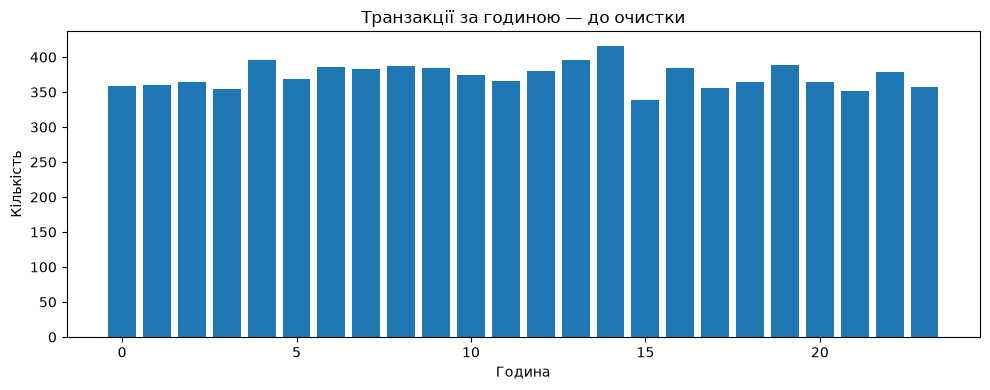

In [11]:
# Дати, часові дірки та логіка часу
op_before = raw['operation_at'].map(parse_mixed_datetime)
post_before = raw['posted_at'].map(parse_mixed_datetime)

print('Не розпарсилось operation_at:', int(op_before.isna().sum()))
print('Не розпарсилось posted_at:', int(post_before.isna().sum()))

valid_time = op_before.notna() & post_before.notna()
time_violation_before = (post_before[valid_time] < op_before[valid_time] - pd.Timedelta(hours=24)).mean() * 100
print(f'posted_at < operation_at більш ніж на 24 год: {time_violation_before:.2f}%')

weekly = pd.DataFrame({'operation_at': op_before}).dropna()
weekly['week'] = weekly['operation_at'].dt.to_period('W').astype(str)
display(weekly['week'].value_counts().sort_index().to_frame('transactions'))

hourly = op_before.dt.hour.value_counts().sort_index()
plt.figure(figsize=(10, 4))
plt.bar(hourly.index, hourly.values)
plt.title('Транзакції за годиною — до очистки')
plt.xlabel('Година')
plt.ylabel('Кількість')
plt.tight_layout()
plt.show()

In [12]:
# Узгодженість валют і FX до очистки
amount_b = raw['amount'].map(parse_number)
fx_b = raw['fx_rate'].map(parse_number)
amount_uah_b = raw['amount_uah'].map(parse_number)
currency_b = raw['currency'].astype(str).str.strip().str.upper()

valid_fx_calc = amount_b.notna() & fx_b.notna() & amount_uah_b.notna() & amount_uah_b.ne(0)
fx_deviation_before = ((amount_b * fx_b - amount_uah_b).abs() / amount_uah_b.abs()).where(valid_fx_calc)

uah_mask = currency_b.eq('UAH') & valid_fx_calc
uah_fx_close = (fx_b[uah_mask].sub(1).abs() <= 0.02).mean() * 100
uah_amount_close = ((amount_b[uah_mask] - amount_uah_b[uah_mask]).abs() / amount_uah_b[uah_mask].abs() <= 0.03).mean() * 100
print(f'UAH: fx_rate≈1: {uah_fx_close:.2f}%')
print(f'UAH: amount≈amount_uah (≤3%): {uah_amount_close:.2f}%')
print(f'FX deviation median: {fx_deviation_before.median()*100:.3f}%')
print(f'FX deviation >3%: {(fx_deviation_before > 0.03).mean()*100:.2f}%')

print('Приклади FX-анomalies:')
display(raw.loc[(fx_b <= 0) | (fx_b > 100) | (fx_deviation_before > 0.03), ['txn_id','amount','currency','amount_uah','fx_rate']].head(10))

UAH: fx_rate≈1: 99.14%
UAH: amount≈amount_uah (≤3%): 96.37%
FX deviation median: 0.160%
FX deviation >3%: 3.07%
Приклади FX-анomalies:


,txn_id,amount,currency,amount_uah,fx_rate
85,TXN0004938,-64.68,UAH,-65.7100,-5.0000
90,TXN0008069,43.24,USD,"2,143.9100",40.6466
120,TXN0000387,-31.63,UAH,-31.1400,-1.0000
177,TXN0002334,"21,86",UAH,20.5700,1.0000
195,TXN0003441,"7,60",UAH,7.3000,1.0000
201,TXN0001926,208.52,UAH,254.0600,1.0000
262,TXN0004704,103.91,UAH,104.8100,-1.0000
305,TXN0001557,161.09,UAH,185.4000,1.0000
337,TXN0004959,46.35,UAH,44.5100,1.0000
386,TXN0004086,-130.51,EUR,"-6,802.8800",45.3291


In [13]:
# Інші аномалії: negative posted, MCC, merchant_name
status_b = raw['status'].astype(str).str.strip().str.lower()
negative_posted_before = ((status_b == 'posted') & amount_b.lt(0) & raw['chargeback_ref'].isna()).sum()
print('Від’ємні posted без chargeback_ref:', int(negative_posted_before))

mcc_s = raw['mcc'].astype('string')
invalid_mcc_before = (~mcc_s.str.fullmatch(r'\d{4}', na=True)) & mcc_s.notna()
print('Невалідні MCC (не 4 цифри):', int(invalid_mcc_before.sum()))

merchant_problem = raw['merchant_name'].astype(str).str.contains(r'\s{2,}|\u200b', regex=True)
print('merchant_name із подвійними/невидимими пробілами:', int(merchant_problem.sum()))
display(raw.loc[merchant_problem, ['txn_id','merchant_name']].head(10))

Від’ємні posted без chargeback_ref: 89
Невалідні MCC (не 4 цифри): 108
merchant_name із подвійними/невидимими пробілами: 391


,txn_id,merchant_name
19,TXN0007754,ANC Pharmacy
66,TXN0006430,​Fashion Point
67,TXN0004784,​WOG
81,TXN0002699,novus
91,TXN0002213,entertainment hub
160,TXN0000553,​Fashion Point
171,TXN0001033,​Cash Point
188,TXN0002202,okko
205,TXN0003769,Game Service
241,TXN0005955,​UPG


In [14]:
# Короткі висновки «до»
display(Markdown(f'''**Висновки до очистки.** У наборі {len(raw):,} рядків виявлено {full_duplicates_before} повних та {near_duplicates_before} майже дублікатів. 
Найбільші пропуски спостерігаються в `city`, `mcc`, `amount_uah` та `fx_rate`, тому прямі агрегації за географією, MCC та гривневим оборотом будуть зміщеними. 
Частина сум зберігається як текст, категорії `channel`, `currency`, `country` мають різні регістри/позначення, що штучно збільшує кількість категорій. 
Також присутні часові порушення ({time_violation_before:.2f}% випадків із затримкою у неправильний бік), некоректні FX та розбіжності між `amount * fx_rate` і `amount_uah`. 
Без очистки це може завищувати або занижувати оборот, спотворювати комісії та давати неправильні висновки за країнами, каналами й MCC.'''))

**Висновки до очистки.** У наборі 8,960 рядків виявлено 180 повних та 180 майже дублікатів. 
Найбільші пропуски спостерігаються в `city`, `mcc`, `amount_uah` та `fx_rate`, тому прямі агрегації за географією, MCC та гривневим оборотом будуть зміщеними. 
Частина сум зберігається як текст, категорії `channel`, `currency`, `country` мають різні регістри/позначення, що штучно збільшує кількість категорій. 
Також присутні часові порушення (0.77% випадків із затримкою у неправильний бік), некоректні FX та розбіжності між `amount * fx_rate` і `amount_uah`. 
Без очистки це може завищувати або занижувати оборот, спотворювати комісії та давати неправильні висновки за країнами, каналами й MCC.

# Блок 3. План та реалізація очистки

Правила нижче роблять кроки максимально **ідемпотентними**: повторне застосування нормалізації не повинно повторно змінювати вже очищені значення.


In [15]:
cleaning_plan = pd.DataFrame([
    ['amount, fee_amount', 'текстові числа, пробіли, коми', 'parse_number → float', 'коректні числові типи', 'NBSP/пробіли видаляються, кома → крапка'],
    ['operation_at, posted_at', '2 формати часу', 'локальний DD.MM → Europe/Kyiv → UTC; ISO → UTC', 'єдина часова зона', 'синтетичне припущення для local format'],
    ['currency', 'lowercase/пробіли', 'trim + upper', '4 стабільні валюти', 'UAH/USD/EUR/PLN'],
    ['channel', 'pos / e-com / Atm', 'словник нормалізації', 'POS/ECOM/ATM', 'невідомі → NA'],
    ['country', 'UK, Ua, пробіли/регістр', 'trim + upper + UK→GB', 'ISO-2', 'невідомі → NA'],
    ['merchant_name', 'регістр, double spaces, zero-width', 'remove invisible + collapse spaces + upper', 'стабільні назви', 'дозволяє near-dedup'],
    ['duplicates', 'exact + near', 'exact drop; потім dedup за txn_id з пріоритетом повнішого рядка', 'унікальний txn_id', 'лог кількості'],
    ['fx_rate', 'NA, <=0, >100, UAH != 1', 'UAH=1; foreign: derive/median by currency', 'валідний FX', 'прапорець fx_changed'],
    ['amount_uah', 'NA / >3% mismatch', 'recalculate amount*fx_rate', 'узгодженість FX', 'прапорець amount_uah_changed'],
    ['posted amount', 'від’ємний без reversal/chargeback', 'abs(amount), recalc amount_uah', 'логічний знак', 'лише status=posted'],
    ['posted_at', 'раніше operation_at', 'очевидні порушення → operation_at + 24h', 'posted_at ≥ operation_at', 'прапорець time_changed'],
    ['chargeback_ref', 'missing/nonexistent/mismatch', 'пошук posted тієї ж картки/валюти; дзеркальні суми', 'валідний зв’язок', 'якщо можливо знайти референс'],
    ['mcc', 'не 4 цифри', 'invalid → NA', '4 digits або NA', 'NA лишається для донаповнення'],
    ['city', 'пропуски', 'не імпутуємо', 'без вигаданого гео', 'пропуски документуються']
], columns=['поле','проблема','метод/правило','очікуваний ефект','примітки'])
display(cleaning_plan)

,поле,проблема,метод/правило,очікуваний ефект,примітки
0,"amount, fee_amount","текстові числа, пробіли, коми",parse_number → float,коректні числові типи,"NBSP/пробіли видаляються, кома → крапка"
1,"operation_at, posted_at",2 формати часу,локальний DD.MM → Europe/Kyiv → UTC; ISO → UTC,єдина часова зона,синтетичне припущення для local format
2,currency,lowercase/пробіли,trim + upper,4 стабільні валюти,UAH/USD/EUR/PLN
3,channel,pos / e-com / Atm,словник нормалізації,POS/ECOM/ATM,невідомі → NA
4,country,"UK, Ua, пробіли/регістр",trim + upper + UK→GB,ISO-2,невідомі → NA
5,merchant_name,"регістр, double spaces, zero-width",remove invisible + collapse spaces + upper,стабільні назви,дозволяє near-dedup
6,duplicates,exact + near,exact drop; потім dedup за txn_id з пріоритето...,унікальний txn_id,лог кількості
7,fx_rate,"NA, <=0, >100, UAH != 1",UAH=1; foreign: derive/median by currency,валідний FX,прапорець fx_changed
8,amount_uah,NA / >3% mismatch,recalculate amount*fx_rate,узгодженість FX,прапорець amount_uah_changed
9,posted amount,від’ємний без reversal/chargeback,"abs(amount), recalc amount_uah",логічний знак,лише status=posted


In [16]:
# --- Журнал змін ---
change_log = []

def add_log(field, rule, count, examples=''):
    change_log.append({
        'field': field,
        'rule': rule,
        'changes_count': int(count),
        'examples': str(examples)[:500]
    })


def sample_examples(before_s, after_s, mask, n=2):
    idx = before_s.index[mask][:n]
    return ' | '.join([f'{before_s.loc[i]} -> {after_s.loc[i]}' for i in idx])

clean = raw.copy()

# Прапорці змін
for flag in [
    'flag_numeric_parsed','flag_currency_changed','flag_channel_changed','flag_country_changed',
    'flag_merchant_changed','flag_fx_changed','flag_amount_uah_changed','flag_time_changed',
    'flag_chargeback_changed','flag_mcc_changed','flag_negative_posted_fixed'
]:
    clean[flag] = False

In [17]:
# 1. Парсинг чисел
for col in ['amount','amount_uah','fx_rate','fee_amount']:
    before = clean[col].copy()
    after = before.map(parse_number)
    # зміною вважаємо значення, яке було непорожнім і мало неканонічний текстовий формат
    mask = before.notna() & before.astype(str).ne(after.astype(str))
    clean[col] = after
    if col in ['amount','fee_amount']:
        clean.loc[mask, 'flag_numeric_parsed'] = True
    add_log(col, 'Парсинг чисел: пробіли/NBSP видалити, десяткову кому перетворити на крапку', mask.sum(), sample_examples(before, after, mask))

# 2. Нормалізація валют
before = clean['currency'].copy()
after = before.astype('string').str.strip().str.upper()
valid_currency = {'UAH','USD','EUR','PLN'}
after = after.where(after.isin(valid_currency), pd.NA)
mask = before.astype('string').fillna('<NA>') != after.astype('string').fillna('<NA>')
clean['currency'] = after
clean.loc[mask, 'flag_currency_changed'] = True
add_log('currency', 'trim + upper; лише UAH/USD/EUR/PLN', mask.sum(), sample_examples(before, after, mask))

# 3. Нормалізація channel
before = clean['channel'].copy()
tmp = before.astype('string').str.strip().str.upper().str.replace('-', '', regex=False).str.replace(' ', '', regex=False)
channel_map = {'POS':'POS','ECOM':'ECOM','ATM':'ATM'}
after = tmp.map(channel_map).astype('string')
mask = before.astype('string').fillna('<NA>') != after.astype('string').fillna('<NA>')
clean['channel'] = after
clean.loc[mask, 'flag_channel_changed'] = True
add_log('channel', 'Нормалізація до POS/ECOM/ATM', mask.sum(), sample_examples(before, after, mask))

# 4. Country ISO-2
before = clean['country'].copy()
tmp = before.astype('string').str.strip().str.upper().replace({'UK':'GB'})
valid_countries = {'UA','PL','DE','CZ','US','FR','IT','ES','GB'}
after = tmp.where(tmp.isin(valid_countries), pd.NA)
mask = before.astype('string').fillna('<NA>') != after.astype('string').fillna('<NA>')
clean['country'] = after
clean.loc[mask, 'flag_country_changed'] = True
add_log('country', 'trim + upper + UK→GB; невідомі → NA', mask.sum(), sample_examples(before, after, mask))

# 5. Merchant normalization
before = clean['merchant_name'].copy()
after = (before.astype('string')
         .str.replace(r'[\u200B-\u200D\uFEFF]', '', regex=True)
         .str.replace(r'\s+', ' ', regex=True)
         .str.strip()
         .str.upper())
mask = before.astype('string').fillna('<NA>') != after.astype('string').fillna('<NA>')
clean['merchant_name'] = after
clean.loc[mask, 'flag_merchant_changed'] = True
add_log('merchant_name', 'Видалити invisible chars, collapse spaces, trim, upper', mask.sum(), sample_examples(before, after, mask))

# 6. Status і note — легка ідемпотентна нормалізація
clean['status'] = clean['status'].astype('string').str.strip().str.lower()
clean['note'] = clean['note'].astype('string').str.strip().replace({'': pd.NA})

In [18]:
# 7. Дати → UTC
for col in ['operation_at','posted_at']:
    before = clean[col].copy()
    after = before.map(parse_mixed_datetime)
    clean[col] = pd.to_datetime(after, utc=True, errors='coerce')
    # Не логують кожен форматний перехід як бізнес-виправлення, але фіксуємо кількість успішних кастів.
    add_log(col, 'Уніфікація часу до timezone-aware UTC', before.notna().sum(), f'example: {before.dropna().iloc[0]} -> {clean[col].dropna().iloc[0]}')

# 8. MCC: 4 цифри або NA
before = clean['mcc'].copy()
after = before.astype('string').str.strip()
valid_mask = after.str.fullmatch(r'\d{4}', na=False)
after = after.where(valid_mask, pd.NA)
mask = before.notna() & after.isna()
clean['mcc'] = after
clean.loc[mask, 'flag_mcc_changed'] = True
add_log('mcc', 'Невалідні коди, що не складаються з 4 цифр → NA', mask.sum(), sample_examples(before, after, mask))

# 9. Повні дублікати
exact_dup_mask = clean.duplicated(subset=list(raw.columns), keep='first')
exact_examples = clean.loc[exact_dup_mask, 'txn_id'].head(2).tolist()
add_log('rows', 'Видалення повних дублікатів', exact_dup_mask.sum(), exact_examples)
clean = clean.loc[~exact_dup_mask].copy()

# 10. Майже дублікати: повторний txn_id. Залишаємо найповніший запис.
clean['_completeness'] = clean[list(raw.columns)].notna().sum(axis=1)
clean = clean.sort_values(['txn_id','_completeness'], ascending=[True,False])
near_dup_mask = clean.duplicated(subset=['txn_id'], keep='first')
near_examples = clean.loc[near_dup_mask, 'txn_id'].head(2).tolist()
add_log('txn_id', 'Near-dedup після текстової нормалізації: один запис на txn_id, пріоритет більш повного', near_dup_mask.sum(), near_examples)
clean = clean.loc[~near_dup_mask].drop(columns=['_completeness']).copy()
clean = clean.sort_values('operation_at').reset_index(drop=True)

In [19]:
# 11. Виправлення від'ємних posted-транзакцій без chargeback_ref
mask = (clean['status'] == 'posted') & clean['chargeback_ref'].isna() & clean['amount'].lt(0)
examples_before = clean.loc[mask, ['txn_id','amount','amount_uah']].head(2).to_dict('records')
clean.loc[mask, 'amount'] = clean.loc[mask, 'amount'].abs()
clean.loc[mask, 'amount_uah'] = clean.loc[mask, 'amount_uah'].abs()
clean.loc[mask, 'flag_negative_posted_fixed'] = True
clean.loc[mask, 'flag_amount_uah_changed'] = True
add_log('amount', 'Для status=posted без chargeback_ref від’ємну суму привести до додатної', mask.sum(), examples_before)

# 12. FX: UAH має fx_rate=1
uah = clean['currency'].eq('UAH')
mask = uah & (clean['fx_rate'].isna() | clean['fx_rate'].sub(1).abs().gt(1e-9))
examples_before = clean.loc[mask, ['txn_id','fx_rate']].head(2).to_dict('records')
clean.loc[mask, 'fx_rate'] = 1.0
clean.loc[mask, 'flag_fx_changed'] = True
add_log('fx_rate', 'Для UAH встановити fx_rate=1', mask.sum(), examples_before)

# 13. Некоректний foreign FX → NA, далі відновлення
invalid_fx = clean['fx_rate'].notna() & ((clean['fx_rate'] <= 0) | (clean['fx_rate'] > 100))
examples_before = clean.loc[invalid_fx, ['txn_id','currency','fx_rate']].head(2).to_dict('records')
clean.loc[invalid_fx, 'fx_rate'] = np.nan
clean.loc[invalid_fx, 'flag_fx_changed'] = True
add_log('fx_rate', 'fx_rate <=0 або >100 → NA перед відновленням', invalid_fx.sum(), examples_before)

# 14. Якщо fx_rate missing, але amount_uah і amount є — виводимо fx_rate з відношення
mask = (clean['currency'] != 'UAH') & clean['fx_rate'].isna() & clean['amount_uah'].notna() & clean['amount'].notna() & clean['amount'].ne(0)
derived = (clean.loc[mask, 'amount_uah'] / clean.loc[mask, 'amount']).abs()
valid_derived = derived.between(0, 100)
idx_valid = derived.index[valid_derived]
clean.loc[idx_valid, 'fx_rate'] = derived.loc[idx_valid]
clean.loc[idx_valid, 'flag_fx_changed'] = True
add_log('fx_rate', 'Відновити як abs(amount_uah / amount), якщо обидві суми відомі', len(idx_valid), clean.loc[idx_valid, ['txn_id','currency','fx_rate']].head(2).to_dict('records'))

# 15. Решту missing foreign FX заповнюємо медіаною валюти
valid_fx_for_median = clean['fx_rate'].between(0, 100) & clean['fx_rate'].notna()
fx_medians = clean.loc[valid_fx_for_median].groupby('currency')['fx_rate'].median().to_dict()
for curr in ['USD','EUR','PLN']:
    mask = clean['currency'].eq(curr) & clean['fx_rate'].isna()
    count = int(mask.sum())
    if count:
        clean.loc[mask, 'fx_rate'] = float(fx_medians.get(curr, base_fx[curr]))
        clean.loc[mask, 'flag_fx_changed'] = True
    add_log('fx_rate', f'Missing {curr}: медіана по валюті', count, fx_medians.get(curr, base_fx[curr]))

# 16. amount_uah: якщо missing — amount * fx_rate
mask = clean['amount_uah'].isna() & clean['amount'].notna() & clean['fx_rate'].notna()
examples_before = clean.loc[mask, ['txn_id','amount','currency','fx_rate']].head(2).to_dict('records')
clean.loc[mask, 'amount_uah'] = (clean.loc[mask, 'amount'] * clean.loc[mask, 'fx_rate']).round(2)
clean.loc[mask, 'flag_amount_uah_changed'] = True
add_log('amount_uah', 'Missing → amount * fx_rate', mask.sum(), examples_before)

# 17. FX consistency: mismatch >3% → перерахувати amount_uah з amount та fx_rate
calc_uah = clean['amount'] * clean['fx_rate']
valid = calc_uah.notna() & clean['amount_uah'].notna() & clean['amount_uah'].ne(0)
dev = ((calc_uah - clean['amount_uah']).abs() / clean['amount_uah'].abs()).where(valid)
mask = dev.gt(0.03)
examples_before = clean.loc[mask, ['txn_id','amount','fx_rate','amount_uah']].head(2).to_dict('records')
clean.loc[mask, 'amount_uah'] = calc_uah.loc[mask].round(2)
clean.loc[mask, 'flag_amount_uah_changed'] = True
add_log('amount_uah', 'Якщо FX-відхилення >3% → amount_uah = amount * fx_rate', mask.sum(), examples_before)

In [20]:
# 18. Час: obvious invalid posted_at < operation_at → operation_at + 24h
mask = clean['posted_at'].notna() & clean['operation_at'].notna() & (clean['posted_at'] < clean['operation_at'])
examples_before = clean.loc[mask, ['txn_id','operation_at','posted_at']].head(2).to_dict('records')
clean.loc[mask, 'posted_at'] = clean.loc[mask, 'operation_at'] + pd.Timedelta(hours=24)
clean.loc[mask, 'flag_time_changed'] = True
add_log('posted_at', 'Якщо posted_at < operation_at → operation_at + 24h', mask.sum(), examples_before)

# 19. Chargeback / reversed: валідація посилань і дзеркальних сум
# Індекс транзакцій оновлюємо після дедуплікації.
by_txn = clean.set_index('txn_id', drop=False)
cb_mask = clean['status'].isin(['chargeback','reversed'])
invalid_ref_mask = cb_mask & (~clean['chargeback_ref'].isin(set(clean['txn_id'])))
invalid_rows = clean.index[invalid_ref_mask]

# Для invalid ref шукаємо posted тієї ж картки та валюти, бажано раніше у часі.
for i in invalid_rows:
    row = clean.loc[i]
    candidates = clean[(clean['status'] == 'posted') &
                       (clean['card_id'] == row['card_id']) &
                       (clean['currency'] == row['currency'])]
    if pd.notna(row['operation_at']):
        earlier = candidates[candidates['operation_at'] <= row['operation_at']]
        if len(earlier):
            candidates = earlier
    if len(candidates):
        ref_row = candidates.sort_values('operation_at').iloc[-1]
        clean.at[i, 'chargeback_ref'] = ref_row['txn_id']
        clean.at[i, 'flag_chargeback_changed'] = True

# Після відновлення ref, синхронізуємо суми та FX із вихідною posted-транзакцією.
by_txn = clean.set_index('txn_id', drop=False)
changed_count = 0
examples = []
for i in clean.index[cb_mask]:
    ref = clean.at[i, 'chargeback_ref']
    if pd.isna(ref) or ref not in by_txn.index:
        continue
    src = by_txn.loc[ref]
    old = (clean.at[i,'amount'], clean.at[i,'amount_uah'], clean.at[i,'fx_rate'])
    clean.at[i, 'amount'] = -abs(float(src['amount']))
    clean.at[i, 'amount_uah'] = -abs(float(src['amount_uah']))
    clean.at[i, 'fx_rate'] = float(src['fx_rate'])
    new = (clean.at[i,'amount'], clean.at[i,'amount_uah'], clean.at[i,'fx_rate'])
    if old != new or clean.at[i, 'flag_chargeback_changed']:
        changed_count += 1
        clean.at[i, 'flag_chargeback_changed'] = True
        clean.at[i, 'flag_amount_uah_changed'] = True
        clean.at[i, 'flag_fx_changed'] = True
        if len(examples) < 2:
            examples.append({'txn_id': clean.at[i,'txn_id'], 'ref': ref, 'before': old, 'after': new})
add_log('chargeback_ref/amount', 'Валідний ref + дзеркальний знак сум для reversal/chargeback', changed_count, examples)

# 20. Підсумковий індикатор будь-якої правки у валютах/FX/часі/категоріях
flag_cols_for_dirty = [
    # KPI 10 за умовою: правки саме у валюті/FX/часі/категоріях.
    'flag_currency_changed','flag_channel_changed','flag_country_changed',
    'flag_fx_changed','flag_time_changed','flag_mcc_changed'
]
clean['was_corrected'] = clean[flag_cols_for_dirty].any(axis=1)

# Округлення фінансових полів
clean['amount'] = clean['amount'].round(2)
clean['amount_uah'] = clean['amount_uah'].round(2)
clean['fx_rate'] = clean['fx_rate'].round(6)
clean['fee_amount'] = clean['fee_amount'].round(2)

# Збереження
clean.to_csv(CLEAN_PATH, index=False, encoding='utf-8-sig')
pd.DataFrame(change_log).to_csv(CHANGE_LOG_PATH, index=False, encoding='utf-8-sig')
print('Clean shape:', clean.shape)
print('Saved:', CLEAN_PATH)
print('Saved:', CHANGE_LOG_PATH)

Clean shape: (8600, 30)
Saved: c:\Users\Andriy\Desktop\lab01_finance_cleaning\data\clean\dataset_clean.csv
Saved: c:\Users\Andriy\Desktop\lab01_finance_cleaning\change_log.csv


In [21]:
# Журнал змін
change_log_df = pd.DataFrame(change_log)
display(change_log_df)
print('Загальна кількість зафіксованих змін за правилами:', int(change_log_df['changes_count'].sum()))

,field,rule,changes_count,examples
0,amount,"Парсинг чисел: пробіли/NBSP видалити, десятков...",897,"407,80 -> 407.8 | 232,35 -> 232.35"
1,amount_uah,"Парсинг чисел: пробіли/NBSP видалити, десятков...",0,
2,fx_rate,"Парсинг чисел: пробіли/NBSP видалити, десятков...",0,
3,fee_amount,"Парсинг чисел: пробіли/NBSP видалити, десятков...",897,"0,61 -> 0.61 | 0,00 -> 0.0"
4,currency,trim + upper; лише UAH/USD/EUR/PLN,449,uah -> UAH | pln -> PLN
5,channel,Нормалізація до POS/ECOM/ATM,716,POS -> POS | POS -> POS
6,country,trim + upper + UK→GB; невідомі → NA,314,UA -> UA | Ua -> UA
7,merchant_name,"Видалити invisible chars, collapse spaces, tri...",7958,Silpo -> SILPO | Entertainment Hub -> ENTERTAI...
8,operation_at,Уніфікація часу до timezone-aware UTC,8960,example: 30.06.2026 22:02 -> 2026-06-30 19:02:...
9,posted_at,Уніфікація часу до timezone-aware UTC,8960,example: 2026-07-02 03:56:56 -> 2026-07-02 03:...


Загальна кількість зафіксованих змін за правилами: 31824


## Валідація якості

Нижче — більше ніж 8 автоматизованих перевірок. Для правил, де пропуски допустимі (`mcc`, `city`), це явно зазначено в умові перевірки.


In [22]:
# --- 12 перевірок якості ---
fx_calc = clean['amount'] * clean['fx_rate']
fx_dev_after = ((fx_calc - clean['amount_uah']).abs() / clean['amount_uah'].abs()).replace([np.inf, -np.inf], np.nan)

validations = []
def add_check(name, passed, details):
    validations.append({'check': name, 'passed': bool(passed), 'details': details})

add_check('1. amount numeric', pd.api.types.is_numeric_dtype(clean['amount']), str(clean['amount'].dtype))
add_check('2. amount_uah numeric', pd.api.types.is_numeric_dtype(clean['amount_uah']), str(clean['amount_uah'].dtype))
add_check('3. UTC datetime types', pd.api.types.is_datetime64_any_dtype(clean['operation_at']) and pd.api.types.is_datetime64_any_dtype(clean['posted_at']), f"{clean['operation_at'].dtype}, {clean['posted_at'].dtype}")
add_check('4. txn_id unique', clean['txn_id'].is_unique, f"duplicates={clean['txn_id'].duplicated().sum()}")
add_check('5. no full duplicates', clean.duplicated(subset=list(raw.columns)).sum() == 0, f"duplicates={clean.duplicated(subset=list(raw.columns)).sum()}")
add_check('6. currency dictionary', clean['currency'].dropna().isin(['UAH','USD','EUR','PLN']).all(), clean['currency'].value_counts(dropna=False).to_dict())
add_check('7. channel dictionary', clean['channel'].dropna().isin(['POS','ECOM','ATM']).all(), clean['channel'].value_counts(dropna=False).to_dict())
add_check('8. country valid ISO-2 dictionary', clean['country'].dropna().isin(sorted(valid_countries)).all(), sorted(clean['country'].dropna().unique().tolist()))
add_check('9. MCC 4 digits or NA', clean['mcc'].dropna().astype(str).str.fullmatch(r'\d{4}').all(), f"NA={clean['mcc'].isna().mean()*100:.2f}%")
add_check('10. posted_at >= operation_at', (clean['posted_at'] >= clean['operation_at']).all(), f"violations={int((clean['posted_at'] < clean['operation_at']).sum())}")
add_check('11. 0 < fx_rate <= 100', clean['fx_rate'].dropna().between(0, 100, inclusive='right').all() and (clean['fx_rate'].dropna() > 0).all(), f"bad={int((~clean['fx_rate'].between(0,100, inclusive='right') | clean['fx_rate'].le(0)).fillna(False).sum())}")
add_check('12. FX mismatch <=3%', (fx_dev_after.dropna() <= 0.03).all(), f"max={fx_dev_after.max()*100:.3f}%")

# Chargeback relations
by_txn = clean.set_index('txn_id', drop=False)
cb = clean[clean['status'].isin(['chargeback','reversed'])].copy()
refs_valid = cb['chargeback_ref'].isin(set(clean['txn_id'])).all()
mirror_ok = True
for _, r in cb.iterrows():
    ref = r['chargeback_ref']
    if pd.isna(ref) or ref not in by_txn.index:
        mirror_ok = False
        break
    src = by_txn.loc[ref]
    if not (np.isclose(r['amount'], -abs(src['amount']), atol=0.01) and np.isclose(r['amount_uah'], -abs(src['amount_uah']), atol=0.02)):
        mirror_ok = False
        break
add_check('13. chargeback_ref valid', refs_valid, f"invalid_refs={int((~cb['chargeback_ref'].isin(set(clean['txn_id']))).sum())}")
add_check('14. chargeback/reversal mirrored amounts', mirror_ok, f"rows_checked={len(cb)}")

validation_df = pd.DataFrame(validations)
display(validation_df)
validation_df.to_csv(OUT_DIR / 'validation_results.csv', index=False, encoding='utf-8-sig')
print('Успішно:', int(validation_df['passed'].sum()), '/', len(validation_df))

,check,passed,details
0,1. amount numeric,True,float64
1,2. amount_uah numeric,True,float64
2,3. UTC datetime types,True,"datetime64[us, UTC], datetime64[us, UTC]"
3,4. txn_id unique,True,duplicates=0
4,5. no full duplicates,True,duplicates=0
5,6. currency dictionary,True,"{'UAH': 6174, 'USD': 997, 'EUR': 909, 'PLN': 520}"
6,7. channel dictionary,True,"{'POS': 5738, 'ECOM': 2128, 'ATM': 734}"
7,8. country valid ISO-2 dictionary,True,"[CZ, DE, ES, FR, GB, IT, PL, UA, US]"
8,9. MCC 4 digits or NA,True,NA=13.70%
9,10. posted_at >= operation_at,True,violations=0


Успішно: 14 / 14


# Блок 4. Статистика «після» та порівняння


In [23]:
# Описова статистика після
numeric_after = clean[['amount','amount_uah','fx_rate','fee_amount']]
display(descriptive_table(numeric_after).round(3))

missing_after = (clean.isna().mean() * 100).sort_values(ascending=False).to_frame('missing_%')
display(missing_after.head(20).round(2))

print('Повні дублікати після:', int(clean.duplicated(subset=list(raw.columns)).sum()))
print('Повторні txn_id після:', int(clean['txn_id'].duplicated().sum()))
print(f'FX >3% після: {(fx_dev_after > 0.03).mean()*100:.3f}%')
print(f'Часових порушень після: {(clean["posted_at"] < clean["operation_at"]).mean()*100:.3f}%')

,count,mean,median,sd,min,max,IQR
field,,,,,,,
amount,8600,203.5600,137.5350,372.4280,"-3,311.6200","10,655.7300",203.1150
amount_uah,8600,"2,213.2210",205.4850,"7,702.1520","-129,509.7000","129,509.7000",986.9850
fx_rate,8600,10.8830,1.0000,17.3070,1.0000,46.5280,9.5570
fee_amount,8600,5.3830,0.0000,43.9680,0.0000,"1,479.4100",0.4700


,missing_%
chargeback_ref,90.5000
note,38.2400
city,15.0000
mcc,13.7000
operation_at,0.0000
client_id,0.0000
amount,0.0000
card_id,0.0000
amount_uah,0.0000
currency,0.0000


Повні дублікати після: 0
Повторні txn_id після: 0
FX >3% після: 0.000%
Часових порушень після: 0.000%


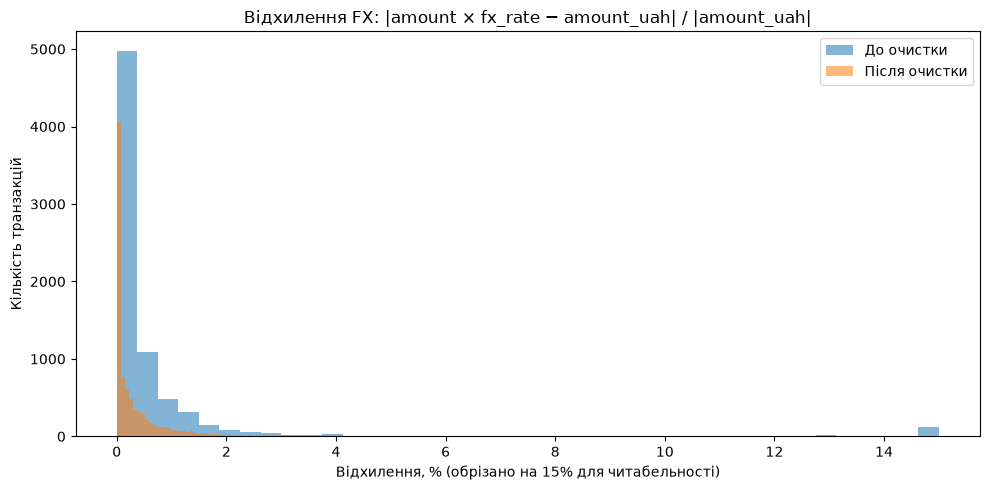

In [24]:
# Візуалізація 1: FX deviation ДО/ПІСЛЯ
before_plot = (fx_deviation_before.dropna().clip(upper=0.15) * 100)
after_plot = (fx_dev_after.dropna().clip(upper=0.15) * 100)

plt.figure(figsize=(10, 5))
plt.hist(before_plot, bins=40, alpha=0.55, label='До очистки')
plt.hist(after_plot, bins=40, alpha=0.55, label='Після очистки')
plt.title('Відхилення FX: |amount × fx_rate − amount_uah| / |amount_uah|')
plt.xlabel('Відхилення, % (обрізано на 15% для читабельності)')
plt.ylabel('Кількість транзакцій')
plt.legend()
plt.tight_layout()
plt.savefig(FIG_DIR / '01_fx_deviation_before_after.png', dpi=140)
plt.show()

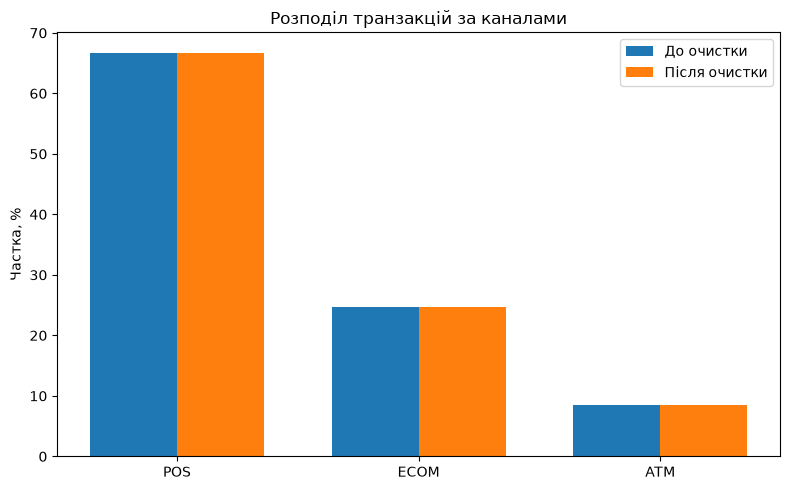

,До очистки,Після очистки
channel,,
POS,66.7500,66.7200
ECOM,24.7500,24.7400
ATM,8.4900,8.5300


In [25]:
# Візуалізація 2: частки каналів ДО/ПІСЛЯ
channel_before_norm = (raw['channel'].astype(str).str.strip().str.upper().str.replace('-', '', regex=False).str.replace(' ', '', regex=False))
channel_before_norm = channel_before_norm.replace({'POS':'POS','ECOM':'ECOM','ATM':'ATM'})
before_share = channel_before_norm.value_counts(normalize=True).reindex(['POS','ECOM','ATM']).fillna(0) * 100
after_share = clean['channel'].value_counts(normalize=True).reindex(['POS','ECOM','ATM']).fillna(0) * 100
channel_compare = pd.DataFrame({'До очистки': before_share, 'Після очистки': after_share})

a = np.arange(len(channel_compare.index))
width = 0.36
plt.figure(figsize=(8, 5))
plt.bar(a - width/2, channel_compare['До очистки'], width, label='До очистки')
plt.bar(a + width/2, channel_compare['Після очистки'], width, label='Після очистки')
plt.xticks(a, channel_compare.index)
plt.ylabel('Частка, %')
plt.title('Розподіл транзакцій за каналами')
plt.legend()
plt.tight_layout()
plt.savefig(FIG_DIR / '02_channel_share_before_after.png', dpi=140)
plt.show()

display(channel_compare.round(2))

In [26]:
# Порівняльна таблиця ключових якостей
comparison_quality = pd.DataFrame({
    'metric': [
        'rows', 'full_duplicates', 'duplicate_txn_id',
        'amount_uah_missing_%', 'fx_rate_missing_%', 'mcc_missing_%', 'city_missing_%',
        'fx_mismatch_gt_3_%', 'time_violation_%'
    ],
    'before': [
        len(raw), full_duplicates_before, int(raw['txn_id'].duplicated().sum()),
        raw['amount_uah'].isna().mean()*100, raw['fx_rate'].isna().mean()*100,
        raw['mcc'].isna().mean()*100, raw['city'].isna().mean()*100,
        (fx_deviation_before > 0.03).mean()*100, time_violation_before
    ],
    'after': [
        len(clean), int(clean.duplicated(subset=list(raw.columns)).sum()), int(clean['txn_id'].duplicated().sum()),
        clean['amount_uah'].isna().mean()*100, clean['fx_rate'].isna().mean()*100,
        clean['mcc'].isna().mean()*100, clean['city'].isna().mean()*100,
        (fx_dev_after > 0.03).mean()*100, (clean['posted_at'] < clean['operation_at']).mean()*100
    ]
})
display(comparison_quality.round(3))

,metric,before,after
0,rows,"8,960.0000","8,600.0000"
1,full_duplicates,180.0000,0.0000
2,duplicate_txn_id,360.0000,0.0000
3,amount_uah_missing_%,9.9550,0.0000
4,fx_rate_missing_%,7.4550,0.0000
5,mcc_missing_%,12.5560,13.6980
6,city_missing_%,14.9110,15.0000
7,fx_mismatch_gt_3_%,3.0690,0.0000
8,time_violation_%,0.7700,0.0000


In [27]:
# Порівняльні висновки «після»
removed = len(raw) - len(clean)
removed_pct = removed / len(raw) * 100
corrected_pct = clean['was_corrected'].mean() * 100

display(Markdown(f'''**Висновки після очистки.** Кількість записів зменшилась з {len(raw):,} до {len(clean):,}; вилучено {removed:,} рядків ({removed_pct:.2f}%), переважно через exact та near-дублі. 
Пропуски `amount_uah` і `fx_rate` були відновлені з доступних фінансових полів або групових медіан, тому гривневий оборот і FX-порівняння стали повнішими. 
Після нормалізації `channel`, `currency` і `country` однакові сутності більше не розбиваються на штучні категорії через регістр, пробіли чи варіант `e-com`. 
Усі виявлені випадки FX-відхилення понад 3% були приведені до правила `amount_uah = amount × fx_rate`, а некоректні курси — відновлені або замінені. 
Часові нелогічності `posted_at < operation_at` усунено, тому середня затримка постингу більше не містить очевидно неможливих від’ємних значень. 
MCC з неправильним форматом переведені в NA, але частина MCC та `city` навмисно лишається пропущеною: їх неможливо чесно відновити без зовнішнього довідника. 
Загалом {corrected_pct:.2f}% очищених транзакцій мали хоча б одну правку у валютах, FX, часі або категоріях; це показує суттєвий початковий рівень «бруду».'''))

**Висновки після очистки.** Кількість записів зменшилась з 8,960 до 8,600; вилучено 360 рядків (4.02%), переважно через exact та near-дублі. 
Пропуски `amount_uah` і `fx_rate` були відновлені з доступних фінансових полів або групових медіан, тому гривневий оборот і FX-порівняння стали повнішими. 
Після нормалізації `channel`, `currency` і `country` однакові сутності більше не розбиваються на штучні категорії через регістр, пробіли чи варіант `e-com`. 
Усі виявлені випадки FX-відхилення понад 3% були приведені до правила `amount_uah = amount × fx_rate`, а некоректні курси — відновлені або замінені. 
Часові нелогічності `posted_at < operation_at` усунено, тому середня затримка постингу більше не містить очевидно неможливих від’ємних значень. 
MCC з неправильним форматом переведені в NA, але частина MCC та `city` навмисно лишається пропущеною: їх неможливо чесно відновити без зовнішнього довідника. 
Загалом 26.20% очищених транзакцій мали хоча б одну правку у валютах, FX, часі або категоріях; це показує суттєвий початковий рівень «бруду».

# Блок 5. 10 KPI з очищених даних

KPI рахуються лише на `dataset_clean.csv`. Для фінансових оборотів використовуємо модуль `amount_uah`, щоб reversal/chargeback не зменшували показник «типового розміру покупки», а **чистий ефект чарджбеків** рахуємо окремо зі знаком.


In [28]:
# Підготовка KPI
clean_kpi = clean.copy()
clean_kpi['abs_amount_uah'] = clean_kpi['amount_uah'].abs()
clean_kpi['posting_delay_h'] = (clean_kpi['posted_at'] - clean_kpi['operation_at']).dt.total_seconds() / 3600

# 1. Кількість транзакцій і частка вилучених дублів
raw_n = len(raw)
clean_n = len(clean_kpi)
removed_duplicate_share = (raw_n - clean_n) / raw_n * 100

# 2. amount_uah summary
amt = clean_kpi['abs_amount_uah'].dropna()
amount_summary = {
    'mean': amt.mean(), 'median': amt.median(),
    'p90': amt.quantile(0.90), 'p95': amt.quantile(0.95)
}

# 3. Частки валюти і channel
currency_share = (clean_kpi['currency'].value_counts(normalize=True) * 100).round(2).to_dict()
channel_share = (clean_kpi['channel'].value_counts(normalize=True) * 100).round(2).to_dict()

# 4. Топ-5 країн для foreign транзакцій (country != UA або currency != UAH)
foreign_txn = clean_kpi[clean_kpi['country'].notna() & (clean_kpi['country'] != 'UA')]
top5_country = (foreign_txn['country'].value_counts(normalize=True).head(5) * 100).round(2).to_dict()

# 5. FX quality buckets
fx_dev_pct = fx_dev_after * 100
fx_buckets = pd.cut(fx_dev_pct, bins=[-np.inf,1,3,np.inf], labels=['узгоджений ≤1%','помірний 1–3%','аномальний >3%'])
fx_bucket_share = (fx_buckets.value_counts(normalize=True).sort_index() * 100).round(2).to_dict()

# 6. Топ-10 MCC за оборотом і NA share
mcc_turnover = (clean_kpi.dropna(subset=['mcc']).groupby('mcc')['abs_amount_uah'].sum().sort_values(ascending=False).head(10))
mcc_na_share = clean_kpi['mcc'].isna().mean() * 100

# 7. Комісії
fee_positive_share = clean_kpi['fee_amount'].gt(0).mean() * 100
effective_fee = (clean_kpi['fee_amount'].abs() / clean_kpi['abs_amount_uah'].replace(0, np.nan))
mean_effective_fee = effective_fee.replace([np.inf,-np.inf], np.nan).mean() * 100

# 8. Затримка постингу
posting_delay_by_currency = clean_kpi.groupby('currency')['posting_delay_h'].mean().round(2).to_dict()
posting_delay_by_channel = clean_kpi.groupby('channel')['posting_delay_h'].mean().round(2).to_dict()

# 9. Chargebacks
chargebacks = clean_kpi[clean_kpi['status'] == 'chargeback']
chargeback_count = len(chargebacks)
chargeback_share = chargeback_count / len(clean_kpi) * 100
chargeback_net_effect = chargebacks['amount_uah'].sum()

# 10. Ступінь бруду
corrected_share = clean_kpi['was_corrected'].mean() * 100

kpi_table = pd.DataFrame([
    [1, 'Транзакції до/після + частка вилучених', f'{raw_n:,} → {clean_n:,}; вилучено {removed_duplicate_share:.2f}%', 'Вилучення дублів зменшує подвійний облік обороту.'],
    [2, 'Середня/медіана amount_uah; p90/p95', f"mean={amount_summary['mean']:.2f}; median={amount_summary['median']:.2f}; p90={amount_summary['p90']:.2f}; p95={amount_summary['p95']:.2f}", 'Медіана стійкіша до великих покупок та ATM.'],
    [3, 'Частки currency та channel', f'currency={currency_share}; channel={channel_share}', 'Показує структуру валют і каналів після нормалізації.'],
    [4, 'Топ-5 foreign країн', str(top5_country), 'Частка серед іноземних/закордонних операцій.'],
    [5, 'Якість FX', str(fx_bucket_share), 'Після очистки аномальна категорія >3% має бути практично 0%.'],
    [6, 'Топ-10 MCC за оборотом + NA', f'top10={mcc_turnover.round(2).to_dict()}; MCC NA={mcc_na_share:.2f}%', 'NA збережено там, де код неможливо чесно відновити.'],
    [7, 'Комісії', f'fee>0: {fee_positive_share:.2f}%; mean effective fee={mean_effective_fee:.3f}%', 'Ефективна комісія = fee_amount / |amount_uah|.'],
    [8, 'Середня затримка постингу', f'by_currency={posting_delay_by_currency}; by_channel={posting_delay_by_channel}', 'Допомагає порівнювати операційні затримки.'],
    [9, 'Chargebacks', f'count={chargeback_count}; share={chargeback_share:.2f}%; net effect={chargeback_net_effect:.2f} UAH', 'Чистий ефект має від’ємний знак.'],
    [10, 'Частка записів з правками', f'{corrected_share:.2f}%', 'Індикатор ступеня початкового «бруду».']
], columns=['KPI','Назва','Значення','Коментар'])

display(kpi_table)
kpi_table.to_csv(OUT_DIR / 'kpi_summary.csv', index=False, encoding='utf-8-sig')

,KPI,Назва,Значення,Коментар
0,1,Транзакції до/після + частка вилучених,"8,960 → 8,600; вилучено 4.02%",Вилучення дублів зменшує подвійний облік обороту.
1,2,Середня/медіана amount_uah; p90/p95,mean=2688.08; median=247.15; p90=7765.96; p95=...,Медіана стійкіша до великих покупок та ATM.
2,3,Частки currency та channel,"currency={'UAH': 71.79, 'USD': 11.59, 'EUR': 1...",Показує структуру валют і каналів після нормал...
3,4,Топ-5 foreign країн,"{'PL': 28.05, 'DE': 15.9, 'CZ': 11.35, 'US': 1...",Частка серед іноземних/закордонних операцій.
4,5,Якість FX,"{'узгоджений ≤1%': 90.59, 'помірний 1–3%': 9.4...",Після очистки аномальна категорія >3% має бути...
5,6,Топ-10 MCC за оборотом + NA,"top10={'6011': 5599526.64, '5732': 1606133.98,...","NA збережено там, де код неможливо чесно відно..."
6,7,Комісії,fee>0: 47.31%; mean effective fee=0.137%,Ефективна комісія = fee_amount / |amount_uah|.
7,8,Середня затримка постингу,"by_currency={'EUR': 36.79, 'PLN': 36.12, 'UAH'...",Допомагає порівнювати операційні затримки.
8,9,Chargebacks,count=390; share=4.53%; net effect=-848447.75 UAH,Чистий ефект має від’ємний знак.
9,10,Частка записів з правками,26.20%,Індикатор ступеня початкового «бруду».


In [29]:
# Детальна таблиця топ-10 MCC
display(mcc_turnover.rename('turnover_uah').to_frame())

,turnover_uah
mcc,
6011,"5,599,526.6400"
5732,"1,606,133.9800"
5411,"1,400,666.7900"
5812,"1,392,672.3600"
5651,"1,332,446.6000"
7995,"1,281,716.4200"
7399,"1,229,335.2800"
4111,"1,228,779.6100"
5912,"1,207,026.2200"


In [30]:
# Для 3 KPI покажемо вплив очистки: оборот, середня ефективна комісія, частка FX >3%
raw_amount_uah_num = raw['amount_uah'].map(parse_number)
raw_fee_num = raw['fee_amount'].map(parse_number)
raw_turnover = raw_amount_uah_num.abs().sum(skipna=True)
clean_turnover = clean_kpi['abs_amount_uah'].sum(skipna=True)

raw_eff_fee = (raw_fee_num.abs() / raw_amount_uah_num.abs().replace(0, np.nan)).replace([np.inf,-np.inf], np.nan).mean() * 100
clean_eff_fee = mean_effective_fee

raw_fx_bad_share = (fx_deviation_before > 0.03).mean() * 100
clean_fx_bad_share = (fx_dev_after > 0.03).mean() * 100

kpi_before_after = pd.DataFrame({
    'KPI': ['Оборот |amount_uah|, UAH', 'Середня ефективна комісія, %', 'FX-відхилення >3%, %'],
    'До': [raw_turnover, raw_eff_fee, raw_fx_bad_share],
    'Після': [clean_turnover, clean_eff_fee, clean_fx_bad_share]
})
display(kpi_before_after.round(3))

,KPI,До,Після
0,"Оборот |amount_uah|, UAH","21,676,810.0300","23,117,509.5800"
1,"Середня ефективна комісія, %",0.1370,0.1370
2,"FX-відхилення >3%, %",3.0690,0.0000


## Підсумок

Лабораторна робота демонструє повний цикл **raw → diagnosis → cleaning → validation → clean → KPI**. `change_log.csv` показує, які правила застосовувалися і скільки значень вони змінили; `validation_results.csv` містить автоматичні перевірки; а графіки у `outputs/figures/` наочно демонструють вплив очистки.

**Обмеження:** пропущені `city` та частина `mcc` не імпутуються, бо без зовнішнього джерела це створило б вигадані дані. Для локального формату `DD.MM.YYYY HH:MM` прийняте документоване синтетичне припущення часової зони `Europe/Kyiv`.
